<a href="https://colab.research.google.com/github/malak-dotcom/life-expectancy-data-processing/blob/main/knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
os.system('pip install streamlit')

0

In [ ]:
#libraries
import joblib
import warnings
warnings.filterwarnings('ignore')
import streamlit as st
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
df=pd.read_csv('advertising.csv')
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


In [ ]:
df.shape


(1000, 10)

In [ ]:
#null
df.isnull().sum()

,0
Daily Time Spent on Site,0
Age,0
Area Income,0
Daily Internet Usage,0
Ad Topic Line,0
City,0
Male,0
Country,0
Timestamp,0
Clicked on Ad,0


In [ ]:
#doublicate
df.drop_duplicates()
df.shape

(1000, 10)

In [ ]:
#outliers
numeric_df = df.select_dtypes(include=[np.number])
q1 = numeric_df.quantile(0.25)
q3 = numeric_df.quantile(0.75)
iqr = q3 - q1
upperlimit = q3 + 1.5 * iqr
lowerlimit = q1 - 1.5 * iqr
for col in numeric_df.columns:
    df[col] = np.where(df[col] < lowerlimit[col], lowerlimit[col], df[col])
    df[col] = np.where(df[col] > upperlimit[col], upperlimit[col], df[col])
df.shape

(1000, 10)

In [ ]:
#log transformation
for col in df:
    if df[col].dtype == 'float64':
        df[col] = np.log1p(df[col])
df.head()
plt.show()

In [ ]:
#encoding
pd.Categorical_df = df.select_dtypes(include='object')
encoder=LabelEncoder()
for col in pd.Categorical_df.columns:
    df[col] = encoder.fit_transform(df[col])
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,4.247781,3.583519,11.032223,5.549426,91,961,0.000000,215,439,0.0
1,4.397285,3.465736,11.133754,5.271819,464,903,0.693147,147,474,0.0
2,4.255187,3.295837,10.998543,5.470168,566,111,0.000000,184,367,0.0
3,4.319486,3.401197,10.911576,5.508943,903,939,0.693147,103,56,0.0
4,4.239454,3.583519,11.210346,5.423098,766,805,0.000000,96,767,0.0


In [ ]:
#scaling
scaler=StandardScaler()
for col in df:
    df[col] = scaler.fit_transform(df[[col]])
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,0.344014,0.000973,0.535063,1.505734,-1.415086,1.700304,-0.962695,1.424572,-0.209578,-1.0
1,0.911177,-0.497131,0.890595,0.411794,-0.122976,1.492546,1.038750,0.451875,-0.088335,-1.0
2,0.372111,-1.215632,0.417123,1.193407,0.230363,-1.344415,-0.962695,0.981136,-0.458994,-1.0
3,0.616038,-0.770064,0.112593,1.346205,1.397766,1.621499,1.038750,-0.177517,-1.536330,-1.0
4,0.312427,0.000973,1.158797,1.007925,0.923184,1.141508,-0.962695,-0.277648,0.926648,-1.0


In [ ]:
#split
X = df.drop('Clicked on Ad', axis=1)
y = df['Clicked on Ad']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(800, 9) (200, 9) (800,) (200,)


In [ ]:
#impalance
df['Clicked on Ad'].value_counts(normalize=True)*100


,proportion
Clicked on Ad,
-1.0,50.0
1.0,50.0


In [ ]:
#colomns reduction
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [ ]:
#grid_searchcv
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
param_grid = {'n_neighbors': [3, 5, 7, 9, 11]}
grid_search = GridSearchCV(knn, param_grid, cv=5)
grid_search.fit(X_train, y_train.astype(int))
print(grid_search.best_params_)

{'n_neighbors': 7}


In [ ]:
#train data val_cross
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
X = df.drop("Clicked on Ad", axis=1)
y = df["Clicked on Ad"].astype(int)
knn = KNeighborsClassifier(n_neighbors=7)
scores = cross_val_score(knn, X, y, cv=5, scoring='accuracy')
print("Accuracy of each fold:", scores)
print("Mean Accuracy:", scores.mean())

Accuracy of each fold: [0.965 0.95  0.975 0.935 0.95 ]
Mean Accuracy: 0.9550000000000001


In [ ]:
#model knn
model = KNeighborsClassifier(n_neighbors=7)
model.fit(X_train, y_train.astype(int))
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test.astype(int), y_pred)*100,'%')

Accuracy: 92.0 %


In [ ]:
joblib.dump(model, 'model.pkl')

['model.pkl']

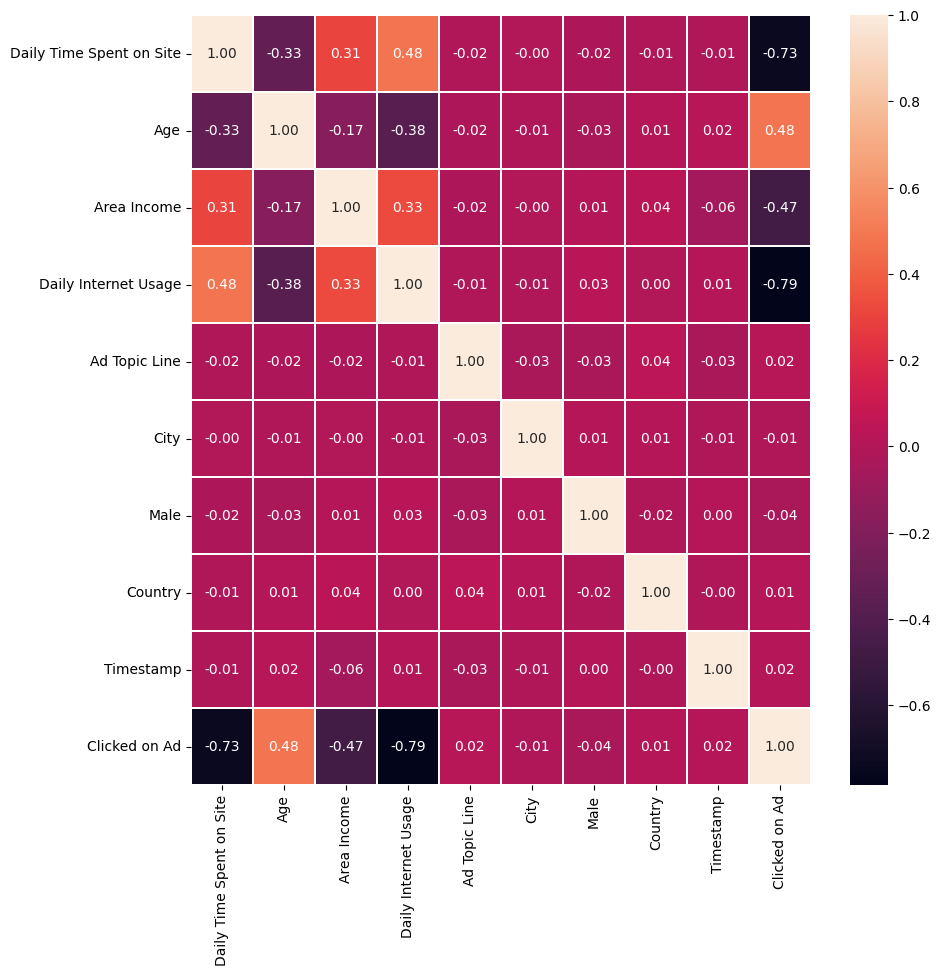

In [ ]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(),  annot=True, fmt='.2f', linewidths=.2)
plt.show()

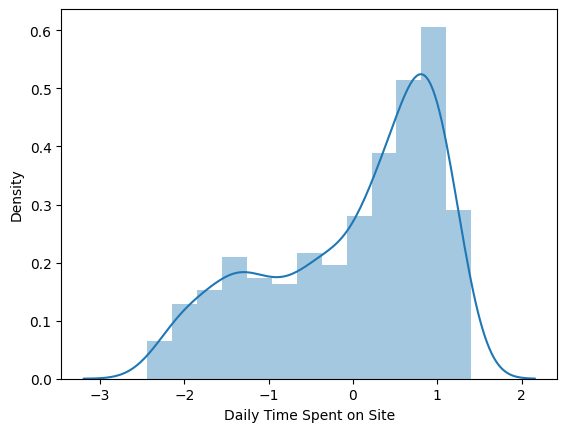

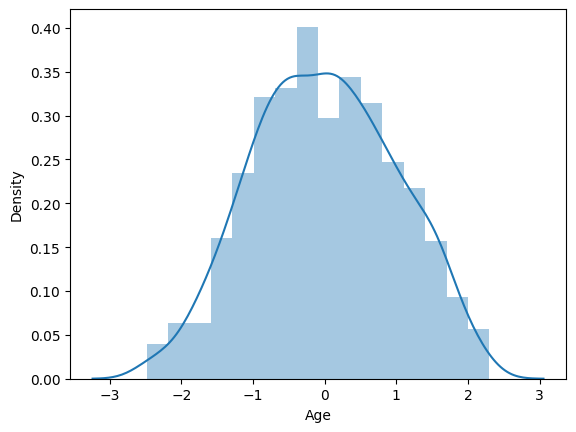

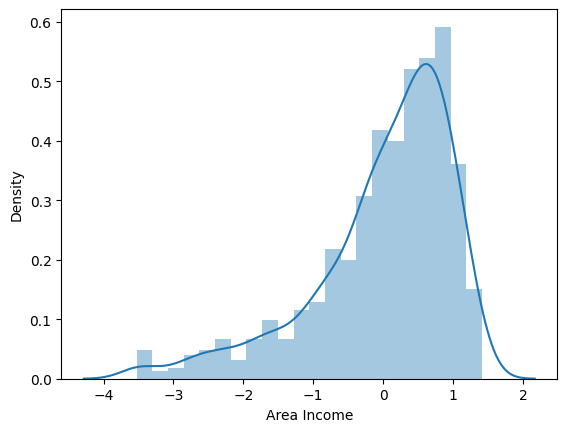

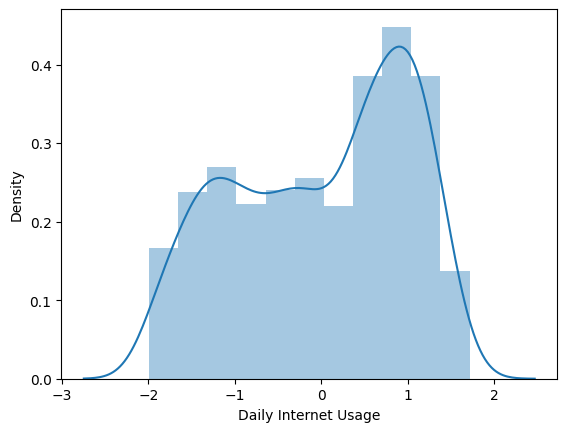

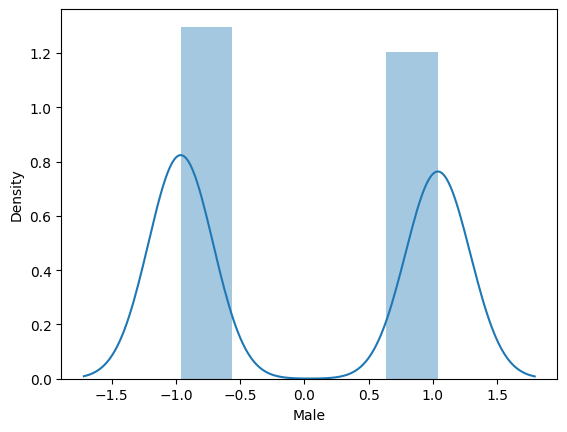

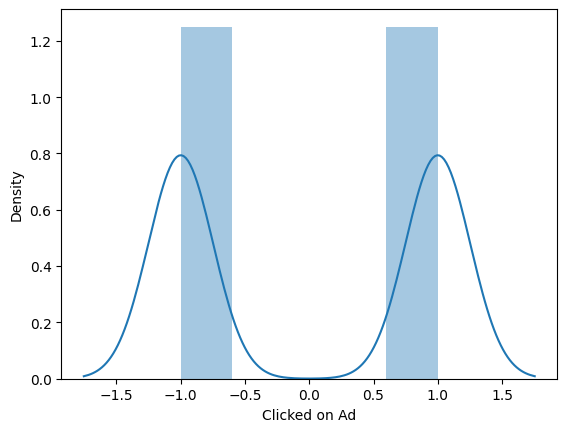

In [ ]:
for n in numeric_df:
    sns.distplot(df[n])
    plt.show()

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV

# Create the model
nb = GaussianNB()

# Hyperparameter grid
param_grid = {
    'var_smoothing': np.logspace(-9, -1, 9)
}

# Grid Search
grid_search = GridSearchCV(
    estimator=nb,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

# Train
grid_search.fit(X_train, y_train.astype(int))

# Best parameter
print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'var_smoothing': np.float64(0.001)}
Best Cross Validation Accuracy: 0.9724999999999999


In [ ]:

!streamlit run app.py



2026-07-31 02:29:06.646 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.60.246.139:8501

